# English–Swedish emotion classification — results

Run the notebook from top to bottom

- Run **cells 1–3 after DEV** to write `outputs/report/selected_prompt_variants_sv.json`
- After TEST evaluations finish, run **all cells** to display Tables 2, 3, 4, 5 and 7, the Jaccard summary, and the Swedish TEST chart
- Scores in Table 2 and the chart come directly from saved **Micro-F1 metrics**
- Bootstrap differences are calculated from matching saved predictions

No LaTeX tables are generated

## 1. Setup

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# find the repository root
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "configs").is_dir() and (p / "outputs").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Run Jupyter inside the project repository")

REPORT_DIR = ROOT / "outputs/report"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
EMOTIONS = ("anger", "anticipation", "disgust", "fear", "joy",
            "sadness", "surprise", "trust")
VARIANTS = ("default", "paraphrase", "no_format_example", "terse")
BOOTSTRAP_SAMPLES = 1000
print("Project:", ROOT)

Project: /scratch/s6865704/llm/LLM_sentiment_classification


## 2. Load saved metrics

In [2]:
def load_metrics(split):
    runs = []
    for family in ("prompting", "peft"):
        folder = ROOT / "outputs/metrics" / family / split
        for path in sorted(folder.glob("*.json")):
            data = json.loads(path.read_text())
            parts = str(data.get("run", path.stem)).split("__")
            if len(parts) != 5 or parts[1] != "sv" or parts[2] not in ("en", "sv"):
                continue

            model, _, language, condition, variant = parts
            if family == "prompting" and condition not in ("zero_shot", "five_shot"):
                continue
            if family == "peft" and not condition.startswith("peft-"):
                continue

            runs.append({**data, "run": "__".join(parts), "split": split,
                         "family": family, "model": model, "language": language,
                         "method": condition if family == "prompting" else "peft",
                         "training": condition.removeprefix("peft-") if family == "peft" else "none",
                         "variant": variant})
    return runs


dev_all = load_metrics("dev")
print("DEV runs found:", len(dev_all))

DEV runs found: 37


## 3. Select DEV prompt variants and save the JSON

This cell only uses DEV results, never TEST results

In [3]:
# select one variant per model and shot condition using both input languages
choices = {}
models = sorted({r["model"] for r in dev_all if r["family"] == "prompting"})
if len(models) != 2:
    raise ValueError("Expected DEV prompting results for Qwen and EuroLLM")

for model in models:
    for method in ("zero_shot", "five_shot"):
        candidates = []
        for variant in VARIANTS:
            runs = [r for r in dev_all if r["model"] == model and
                    r["method"] == method and r["variant"] == variant]
            if len(runs) != 2 or {r["language"] for r in runs} != {"en", "sv"}:
                raise ValueError(f"Missing DEV runs for {model}, {method}, {variant}")
            micro = np.mean([float(r["micro_f1"]) for r in runs])
            jaccard = np.mean([float(r["sample_jaccard"]) for r in runs])
            candidates.append((micro, jaccard, variant))

        # use micro-f1, then jaccard, then the variant name to break ties
        best = sorted(candidates, key=lambda x: (-x[0], -x[1], x[2]))[0][2]
        for language in ("en", "sv"):
            choices[f"{model}__sv__{language}__{method}"] = best

selection_path = REPORT_DIR / "selected_prompt_variants_sv.json"

# keep the previous selection if test prompting has already been evaluated
existing = json.loads(selection_path.read_text()) if selection_path.exists() else None
test_folder = ROOT / "outputs/metrics/prompting/test"
if existing is not None and existing != choices and any(test_folder.glob("*__sv__*.json")):
    raise ValueError("DEV selection changed after TEST prompting: check existing results")

selection_path.write_text(json.dumps(choices, indent=2) + "\n")
print("Saved:", selection_path)
display(pd.DataFrame([{"Experiment": key, "Variant": value}
                      for key, value in choices.items()]))

Saved: /scratch/s6865704/llm/LLM_sentiment_classification/outputs/report/selected_prompt_variants_sv.json


,Experiment,Variant
0,EuroLLM-9B-Instruct__sv__en__zero_shot,paraphrase
1,EuroLLM-9B-Instruct__sv__sv__zero_shot,paraphrase
2,EuroLLM-9B-Instruct__sv__en__five_shot,paraphrase
3,EuroLLM-9B-Instruct__sv__sv__five_shot,paraphrase
4,Qwen2.5-3B-Instruct__sv__en__zero_shot,terse
5,Qwen2.5-3B-Instruct__sv__sv__zero_shot,terse
6,Qwen2.5-3B-Instruct__sv__en__five_shot,terse
7,Qwen2.5-3B-Instruct__sv__sv__five_shot,terse


## 4. Keep the selected DEV and TEST runs

In [4]:
def selected_runs(runs):
    chosen = []
    for run in runs:
        key = f'{run["model"]}__sv__{run["language"]}__{run["method"]}'
        if run["family"] == "peft" or run["variant"] == choices.get(key):
            chosen.append(run)
    return chosen


def locate(runs, model, method, language, training="none"):
    matches = [r for r in runs if model in r["model"] and
               r["method"] == method and r["language"] == language and
               (method != "peft" or r["training"] == training)]
    if len(matches) > 1:
        raise ValueError(f"Duplicate runs for {model}, {method}, {language}, {training}")
    return matches[0] if matches else None


dev = selected_runs(dev_all)
test = selected_runs(load_metrics("test"))
print(f"Selected {len(dev)} DEV and {len(test)} TEST runs")

Selected 13 DEV and 13 TEST runs


## 5. Load predictions and compute output statistics

In [5]:
cache = {}


def predictions(run):
    key = (run["family"], run["split"], run["run"])
    if key not in cache:
        path = ROOT / "outputs/predictions" / run["family"] / run["split"] / (run["run"] + ".jsonl")
        if not path.exists():
            raise FileNotFoundError(path)
        records = [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
        ids = [str(r["alignment_id"]) for r in records]
        if len(ids) != len(set(ids)):
            raise ValueError(f"Duplicate alignment IDs in {path}")
        cache[key] = records
    return cache[key]


def parsed_labels(raw):
    # accept only non-empty json lists of permitted emotion labels
    try:
        values = json.loads(raw.strip())
        if not isinstance(values, list) or not values or not all(isinstance(v, str) for v in values):
            return []
        labels = {" ".join(v.split()).lower() for v in values}
        return [v for v in EMOTIONS if v in labels] if labels <= set(EMOTIONS) else []
    except (ValueError, AttributeError, TypeError):
        return []


def output_stats(run):
    rows = predictions(run)
    output = [parsed_labels(r.get("raw_output")) for r in rows]
    # count malformed responses and empty predictions together
    empty_rate = sum(not labels for labels in output) / len(rows)
    return {"Empty answers (%)": 100 * empty_rate,
            "Labels per text": np.mean([len(labels) for labels in output]),
            "Malformed": empty_rate,
            "Strict JSON": 1 - empty_rate,
            "Gold labels per text": np.mean([len(r["gold"]) for r in rows])}


def label_matrix(labels):
    if not set(labels) <= set(EMOTIONS):
        raise ValueError(f"Unexpected emotion labels: {labels}")
    return np.array([label in labels for label in EMOTIONS], dtype=bool)

## 6. Table 2 — Qwen Micro-F1 on TEST (DEV in parentheses)

In [6]:
methods = [
    ("Prompting", "Zero-shot", "—", "zero_shot", "none"),
    ("Prompting", "Five-shot", "—", "five_shot", "none"),
    ("PEFT (QLoRA)", "English-only", "English", "peft", "english"),
    ("PEFT (QLoRA)", "Swedish-only", "Swedish", "peft", "target"),
    ("PEFT (QLoRA)", "Bilingual", "English + Swedish", "peft", "bilingual"),
]


def formatted_micro(method, language, training):
    result = locate(test, "Qwen", method, language, training)
    validation = locate(dev, "Qwen", method, language, training)
    if result is None:
        return "—"
    test_score = float(result["micro_f1"])
    dev_score = f'{float(validation["micro_f1"]):.3f}' if validation else "—"
    return f"{test_score:.3f} ({dev_score})"


# use the saved micro-f1 metrics directly
rows = [{"Group": group, "Method": name, "Training data": data,
         "English": formatted_micro(method, "en", training),
         "Swedish": formatted_micro(method, "sv", training)}
        for group, name, data, method, training in methods]
table2 = pd.DataFrame(rows).set_index(["Group", "Method"])
display(table2)

Training data        English        Swedish
Group        Method                                                       
Prompting    Zero-shot                     —  0.349 (0.368)  0.292 (0.293)
             Five-shot                     —  0.369 (0.392)  0.314 (0.338)
PEFT (QLoRA) English-only            English  0.455 (0.459)  0.345 (0.356)
             Swedish-only            Swedish              —  0.356 (0.377)
             Bilingual     English + Swedish  0.462 (0.480)  0.363 (0.403)

## 7. Table 3 — Qwen output behavior on TEST

In [7]:
rows = []
for group, name, _, method, training in methods:
    row = {("", "Group"): group, ("", "Method"): name}
    for language, label in (("en", "English"), ("sv", "Swedish")):
        run = locate(test, "Qwen", method, language, training)
        stats = output_stats(run) if run else {}
        for metric in ("Empty answers (%)", "Labels per text"):
            row[(metric, label)] = stats.get(metric, np.nan)
    rows.append(row)

# the reference row contains labels rather than model outputs
reference = {("", "Group"): "Reference", ("", "Method"): "Gold standard"}
for language, label in (("en", "English"), ("sv", "Swedish")):
    run = locate(test, "Qwen", "zero_shot", language)
    reference[("Empty answers (%)", label)] = np.nan
    reference[("Labels per text", label)] = output_stats(run)["Gold labels per text"] if run else np.nan
rows.append(reference)

table3 = pd.DataFrame(rows).set_index([("", "Group"), ("", "Method")])
table3.index.names = ["Group", "Method"]
table3.columns = pd.MultiIndex.from_tuples(table3.columns)
display(table3.round(2).fillna("—"))

Empty answers (%) Labels per text  \
                                     English         English   
Group        Method                                            
Prompting    Zero-shot                   6.0            1.03   
             Five-shot                   6.0            1.07   
PEFT (QLoRA) English-only                0.0            1.21   
             Swedish-only                  —               —   
             Bilingual                   0.0            1.22   
Reference    Gold standard                 —            1.42   

                           Empty answers (%) Labels per text  
                                     Swedish         Swedish  
Group        Method                                           
Prompting    Zero-shot                   2.4            0.99  
             Five-shot                   2.4            1.02  
PEFT (QLoRA) English-only                0.0            1.04  
             Swedish-only                0.0            1.25  
             Bilingual                   0.0            1.24  
Reference    Gold standard                 —            1.42

## 8. Table 5 — DEV output-format reliability

In [8]:
rows = []
for model in ("Qwen", "EuroLLM"):
    for language in ("en", "sv"):
        for method, label in (("zero_shot", "Zero-shot"), ("five_shot", "Five-shot")):
            run = locate(dev, model, method, language)
            stats = output_stats(run) if run else {}
            rows.append({"Model": "Qwen2.5-3B-Instruct" if model == "Qwen" else "EuroLLM-9B-Instruct",
                         "Language": language, "Condition": label,
                         "Malformed": stats.get("Malformed", np.nan),
                         "Strict JSON": stats.get("Strict JSON", np.nan)})

table5 = pd.DataFrame(rows).set_index(["Model", "Language", "Condition"])
display(table5.round(3).fillna("—"))

Malformed  Strict JSON
Model               Language Condition                        
Qwen2.5-3B-Instruct en       Zero-shot      0.050        0.950
                             Five-shot      0.054        0.946
                    sv       Zero-shot      0.036        0.964
                             Five-shot      0.040        0.960
EuroLLM-9B-Instruct en       Zero-shot      0.030        0.970
                             Five-shot      0.004        0.996
                    sv       Zero-shot      0.004        0.996
                             Five-shot      0.004        0.996

## 9. Check saved scores against predictions

This check helps find outdated metrics or prediction files before reporting bootstrap results

In [9]:
# check that saved micro-f1 values agree with the prediction files
mismatches = []
for run in dev + test:
    rows = predictions(run)
    gold = np.stack([label_matrix(r["gold"]) for r in rows])
    pred = np.stack([label_matrix(r["pred"]) for r in rows])
    tp, fp, fn = (gold & pred).sum(), (~gold & pred).sum(), (gold & ~pred).sum()
    calculated = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    saved = float(run["micro_f1"])
    if abs(calculated - saved) > 0.001:
        mismatches.append({"Run": run["run"], "Saved Micro-F1": saved,
                           "Predictions Micro-F1": calculated})

if mismatches:
    print("Warning: saved metrics and predictions disagree")
    display(pd.DataFrame(mismatches).round(4))
else:
    print("Saved Micro-F1 metrics match predictions")

Saved Micro-F1 metrics match predictions


## 10. Paired bootstrap helper for Micro-F1 and sample Jaccard

Bootstrap comparisons are calculated on matching alignment IDs and gold labels

In [10]:
def paired_bootstrap(run_a, run_b, metric, seed=42):
    a = {str(r["alignment_id"]): r for r in predictions(run_a)}
    b = {str(r["alignment_id"]): r for r in predictions(run_b)}
    shared = sorted(a.keys() & b.keys())

    # skip comparisons if the shared set is too small
    if len(shared) < 20 or min(len(shared) / len(a), len(shared) / len(b)) < 0.80:
        return "—"

    gold = np.stack([label_matrix(a[i]["gold"]) for i in shared])
    other_gold = np.stack([label_matrix(b[i]["gold"]) for i in shared])
    if not np.array_equal(gold, other_gold):
        raise ValueError("Gold labels differ for matched alignment IDs")

    pred_a = np.stack([label_matrix(a[i]["pred"]) for i in shared])
    pred_b = np.stack([label_matrix(b[i]["pred"]) for i in shared])

    # calculate the statistic after selecting example indices
    def score(pred, indices):
        y, p = gold[indices], pred[indices]
        if metric == "jaccard":
            intersection = (y & p).sum(axis=1)
            union = (y | p).sum(axis=1)
            return np.mean(np.divide(intersection, union, out=np.zeros(len(union), dtype=float), where=union > 0))
        tp, fp, fn = (y & p).sum(), (~y & p).sum(), (y & ~p).sum()
        return 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0

    indices = np.arange(len(shared))
    delta = score(pred_b, indices) - score(pred_a, indices)
    rng = np.random.default_rng(seed)
    samples = rng.integers(len(shared), size=(BOOTSTRAP_SAMPLES, len(shared)))
    changes = [score(pred_b, sample) - score(pred_a, sample) for sample in samples]
    low, high = np.quantile(changes, [0.025, 0.975])
    mark = " †" if len(shared) != len(a) or len(shared) != len(b) else ""
    return f"{delta:+.3f} [{low:.3f}, {high:.3f}]{mark}"

## 11. Tables 4 and 7 — paired Micro-F1 differences


In [11]:
# each row describes experiment b minus experiment a
comparisons = [
    ("PEFT vs. prompting", "English", "English-only − zero-shot", ("zero_shot", "en", "none"), ("peft", "en", "english")),
    ("PEFT vs. prompting", "English", "English-only − five-shot", ("five_shot", "en", "none"), ("peft", "en", "english")),
    ("PEFT vs. prompting", "English", "Bilingual − zero-shot", ("zero_shot", "en", "none"), ("peft", "en", "bilingual")),
    ("PEFT vs. prompting", "English", "Bilingual − five-shot", ("five_shot", "en", "none"), ("peft", "en", "bilingual")),
    ("PEFT vs. prompting", "Swedish", "English-only − zero-shot", ("zero_shot", "sv", "none"), ("peft", "sv", "english")),
    ("PEFT vs. prompting", "Swedish", "English-only − five-shot", ("five_shot", "sv", "none"), ("peft", "sv", "english")),
    ("PEFT vs. prompting", "Swedish", "Swedish-only − zero-shot", ("zero_shot", "sv", "none"), ("peft", "sv", "target")),
    ("PEFT vs. prompting", "Swedish", "Swedish-only − five-shot", ("five_shot", "sv", "none"), ("peft", "sv", "target")),
    ("PEFT vs. prompting", "Swedish", "Bilingual − zero-shot", ("zero_shot", "sv", "none"), ("peft", "sv", "bilingual")),
    ("PEFT vs. prompting", "Swedish", "Bilingual − five-shot", ("five_shot", "sv", "none"), ("peft", "sv", "bilingual")),
    ("Between PEFT conditions", "Swedish", "Swedish-only − English-only", ("peft", "sv", "english"), ("peft", "sv", "target")),
    ("Between PEFT conditions", "Swedish", "Bilingual − English-only", ("peft", "sv", "english"), ("peft", "sv", "bilingual")),
    ("Between PEFT conditions", "Swedish", "Bilingual − Swedish-only", ("peft", "sv", "target"), ("peft", "sv", "bilingual")),
    ("Between PEFT conditions", "English", "Bilingual − English-only", ("peft", "en", "english"), ("peft", "en", "bilingual")),
    ("Language gap (Swedish − English)", "—", "Zero-shot", ("zero_shot", "en", "none"), ("zero_shot", "sv", "none")),
    ("Language gap (Swedish − English)", "—", "Five-shot", ("five_shot", "en", "none"), ("five_shot", "sv", "none")),
    ("Language gap (Swedish − English)", "—", "English-only PEFT", ("peft", "en", "english"), ("peft", "sv", "english")),
    ("Language gap (Swedish − English)", "—", "Bilingual PEFT", ("peft", "en", "bilingual"), ("peft", "sv", "bilingual")),
]


def comparison_table(metric):
    rows = []
    for section, language, label, a, b in comparisons:
        row = {"Section": section, "Language": language, "Comparison (B − A)": label}
        for split, runs in (("TEST", test), ("DEV", dev)):
            run_a = locate(runs, "Qwen", *a)
            run_b = locate(runs, "Qwen", *b)
            row[split] = paired_bootstrap(run_a, run_b, metric) if run_a and run_b else "—"
        rows.append(row)
    return pd.DataFrame(rows).set_index(["Section", "Language", "Comparison (B − A)"])


table7 = comparison_table("micro_f1")
summary = [("English", "English-only − zero-shot"),
           ("English", "English-only − five-shot"),
           ("Swedish", "English-only − zero-shot"),
           ("Swedish", "English-only − five-shot"),
           ("Swedish", "Swedish-only − zero-shot"),
           ("Swedish", "Swedish-only − five-shot"),
           ("Swedish", "Swedish-only − English-only")]
table4 = table7.loc[[idx for idx in table7.index if (idx[1], idx[2]) in summary]]
print("Table 4 — Micro-F1 bootstrap summary")
display(table4)
print("Table 7 — Full Micro-F1 bootstrap comparisons")
display(table7)

Table 4 — Micro-F1 bootstrap summary


TEST  \
Section                 Language Comparison (B − A)                                    
PEFT vs. prompting      English  English-only − zero-shot      +0.107 [0.059, 0.158]   
                                 English-only − five-shot      +0.087 [0.043, 0.137]   
                        Swedish  English-only − zero-shot     +0.053 [-0.005, 0.111]   
                                 English-only − five-shot     +0.031 [-0.027, 0.085]   
                                 Swedish-only − zero-shot      +0.064 [0.008, 0.123]   
                                 Swedish-only − five-shot     +0.042 [-0.012, 0.094]   
Between PEFT conditions Swedish  Swedish-only − English-only  +0.011 [-0.028, 0.055]   

                                                                                 DEV  
Section                 Language Comparison (B − A)                                   
PEFT vs. prompting      English  English-only − zero-shot      +0.091 [0.059, 0.127]  
                                 English-only − five-shot      +0.067 [0.030, 0.105]  
                        Swedish  English-only − zero-shot      +0.063 [0.025, 0.105]  
                                 English-only − five-shot     +0.018 [-0.021, 0.059]  
                                 Swedish-only − zero-shot      +0.084 [0.043, 0.121]  
                                 Swedish-only − five-shot      +0.039 [0.000, 0.080]  
Between PEFT conditions Swedish  Swedish-only − English-only  +0.021 [-0.010, 0.053]

Table 7 — Full Micro-F1 bootstrap comparisons


TEST  \
Section                          Language Comparison (B − A)                                     
PEFT vs. prompting               English  English-only − zero-shot       +0.107 [0.059, 0.158]   
                                          English-only − five-shot       +0.087 [0.043, 0.137]   
                                          Bilingual − zero-shot          +0.114 [0.063, 0.165]   
                                          Bilingual − five-shot          +0.094 [0.044, 0.145]   
                                 Swedish  English-only − zero-shot      +0.053 [-0.005, 0.111]   
                                          English-only − five-shot      +0.031 [-0.027, 0.085]   
                                          Swedish-only − zero-shot       +0.064 [0.008, 0.123]   
                                          Swedish-only − five-shot      +0.042 [-0.012, 0.094]   
                                          Bilingual − zero-shot          +0.071 [0.014, 0.129]   
                                          Bilingual − five-shot         +0.049 [-0.007, 0.103]   
Between PEFT conditions          Swedish  Swedish-only − English-only   +0.011 [-0.028, 0.055]   
                                          Bilingual − English-only      +0.018 [-0.026, 0.064]   
                                          Bilingual − Swedish-only      +0.007 [-0.028, 0.044]   
                                 English  Bilingual − English-only      +0.007 [-0.029, 0.042]   
Language gap (Swedish − English) —        Zero-shot                    -0.057 [-0.106, -0.007]   
                                          Five-shot                    -0.055 [-0.101, -0.001]   
                                          English-only PEFT            -0.111 [-0.165, -0.055]   
                                          Bilingual PEFT               -0.099 [-0.151, -0.047]   

                                                                                           DEV  
Section                          Language Comparison (B − A)                                    
PEFT vs. prompting               English  English-only − zero-shot       +0.091 [0.059, 0.127]  
                                          English-only − five-shot       +0.067 [0.030, 0.105]  
                                          Bilingual − zero-shot          +0.112 [0.078, 0.149]  
                                          Bilingual − five-shot          +0.088 [0.050, 0.127]  
                                 Swedish  English-only − zero-shot       +0.063 [0.025, 0.105]  
                                          English-only − five-shot      +0.018 [-0.021, 0.059]  
                                          Swedish-only − zero-shot       +0.084 [0.043, 0.121]  
                                          Swedish-only − five-shot       +0.039 [0.000, 0.080]  
                                          Bilingual − zero-shot          +0.110 [0.071, 0.150]  
                                          Bilingual − five-shot          +0.065 [0.027, 0.106]  
Between PEFT conditions          Swedish  Swedish-only − English-only   +0.021 [-0.010, 0.053]  
                                          Bilingual − English-only       +0.047 [0.017, 0.079]  
                                          Bilingual − Swedish-only      +0.026 [-0.001, 0.053]  
                                 English  Bilingual − English-only      +0.021 [-0.002, 0.043]  
Language gap (Swedish − English) —        Zero-shot                    -0.075 [-0.111, -0.036]  
                                          Five-shot                    -0.054 [-0.090, -0.018]  
                                          English-only PEFT            -0.104 [-0.143, -0.065]  
                                          Bilingual PEFT               -0.077 [-0.113, -0.042]

## 12. Table 4 — sample Jaccard differences


In [12]:
# use the same comparisons with the sample jaccard metric
table4_jaccard_full = comparison_table("jaccard")
table4_jaccard = table4_jaccard_full.loc[
    [idx for idx in table4_jaccard_full.index if (idx[1], idx[2]) in summary]
]
display(table4_jaccard)

TEST  \
Section                 Language Comparison (B − A)                                    
PEFT vs. prompting      English  English-only − zero-shot      +0.098 [0.050, 0.150]   
                                 English-only − five-shot      +0.097 [0.052, 0.146]   
                        Swedish  English-only − zero-shot     +0.040 [-0.017, 0.097]   
                                 English-only − five-shot     +0.032 [-0.023, 0.087]   
                                 Swedish-only − zero-shot     +0.041 [-0.012, 0.099]   
                                 Swedish-only − five-shot     +0.033 [-0.018, 0.085]   
Between PEFT conditions Swedish  Swedish-only − English-only  +0.001 [-0.037, 0.045]   

                                                                                 DEV  
Section                 Language Comparison (B − A)                                   
PEFT vs. prompting      English  English-only − zero-shot      +0.078 [0.044, 0.115]  
                                 English-only − five-shot      +0.060 [0.022, 0.097]  
                        Swedish  English-only − zero-shot      +0.058 [0.019, 0.099]  
                                 English-only − five-shot     +0.025 [-0.014, 0.065]  
                                 Swedish-only − zero-shot      +0.055 [0.013, 0.095]  
                                 Swedish-only − five-shot     +0.023 [-0.013, 0.062]  
Between PEFT conditions Swedish  Swedish-only − English-only  -0.003 [-0.034, 0.029]

## 13. Swedish TEST Micro-F1 figure


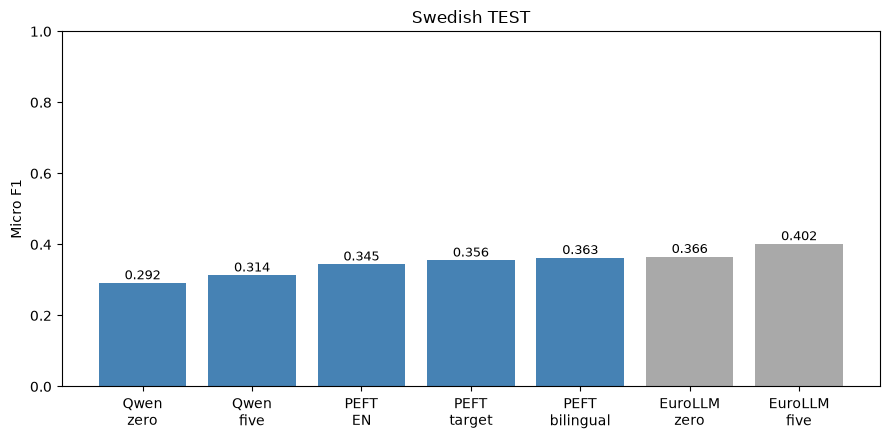

Saved: /scratch/s6865704/llm/LLM_sentiment_classification/outputs/report/sv_test_method_comparison.png


In [13]:
# read the same saved micro-f1 values used in table 2
labels = ["Qwen\nzero", "Qwen\nfive", "PEFT\nEN", "PEFT\ntarget",
          "PEFT\nbilingual", "EuroLLM\nzero", "EuroLLM\nfive"]
settings = [("Qwen", "zero_shot", "none"), ("Qwen", "five_shot", "none"),
            ("Qwen", "peft", "english"), ("Qwen", "peft", "target"),
            ("Qwen", "peft", "bilingual"), ("EuroLLM", "zero_shot", "none"),
            ("EuroLLM", "five_shot", "none")]

scores = []
for model, method, training in settings:
    run = locate(test, model, method, "sv", training)
    if run is None:
        raise ValueError(f"Missing Swedish TEST metrics for {model}, {method}, {training}")
    scores.append(float(run["micro_f1"]))

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, scores, color=["steelblue"] * 5 + ["darkgray"] * 2)
ax.set(title="Swedish TEST", ylabel="Micro F1", ylim=(0, 1))
for bar, value in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01,
            f"{value:.3f}", ha="center", fontsize=9)
plt.tight_layout()
figure_path = REPORT_DIR / "sv_test_method_comparison.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)